# CPSC 480 – Project 3: Support Vector Machines and Decision Trees

## Project Description

This project builds and compares three classifiers on the same real-world dataset, the **Iris flower dataset** (collected by Edgar Anderson and published by R.A. Fisher in 1936, included in scikit-learn):

1. **SVM without a kernel (linear SVM):** separates the classes with straight (hyperplane) boundaries
2. **SVM with a kernel (RBF / Gaussian kernel):** uses the kernel trick to learn curved, non-linear boundaries
3. **Decision Tree:** a rule-based model that splits on one feature at a time, visualized as a tree diagram

**Task:** predict a flower's species (*setosa*, *versicolor* or *virginica*) from four measurements: sepal length, sepal width, petal length and petal width.

**Steps:** load and inspect the data → visualize it → split it into training and testing sets → scale the features → train the three models → compare their test accuracy and confusion matrices → draw conclusions.

In [1]:
# Data handling and plotting libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# scikit-learn: dataset, data splitting, scaling, models, and evaluation tools
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

## 1. Load and Inspect the Data

The Iris dataset has **150 samples**, 50 for each species, and **4 numeric features** measured in centimeters. Below we load it into a DataFrame, add a readable `species` column, and check the data's structure and summary statistics.

In [2]:
# Load the Iris dataset as a pandas DataFrame (4 features + numeric target)
iris = load_iris(as_frame=True)
df = iris.frame

# Add a readable species name column by mapping target 0/1/2 to setosa/versicolor/virginica
df['species'] = df['target'].map(dict(enumerate(iris.target_names)))

# Preview the first five rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [3]:
# Check column types, row count, and whether any values are missing
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


In [4]:
# Summary statistics (mean, std, min, quartiles, max) for each numeric column
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


## 2. Exploratory Data Analysis

Before training, we look at how the features relate to each other and to the species:

- **Pair plot:** a scatter plot for every pair of features, colored by species, showing which features separate the classes.
- **Correlation heatmap:** shows how strongly the features move together. Highly correlated features carry overlapping information.

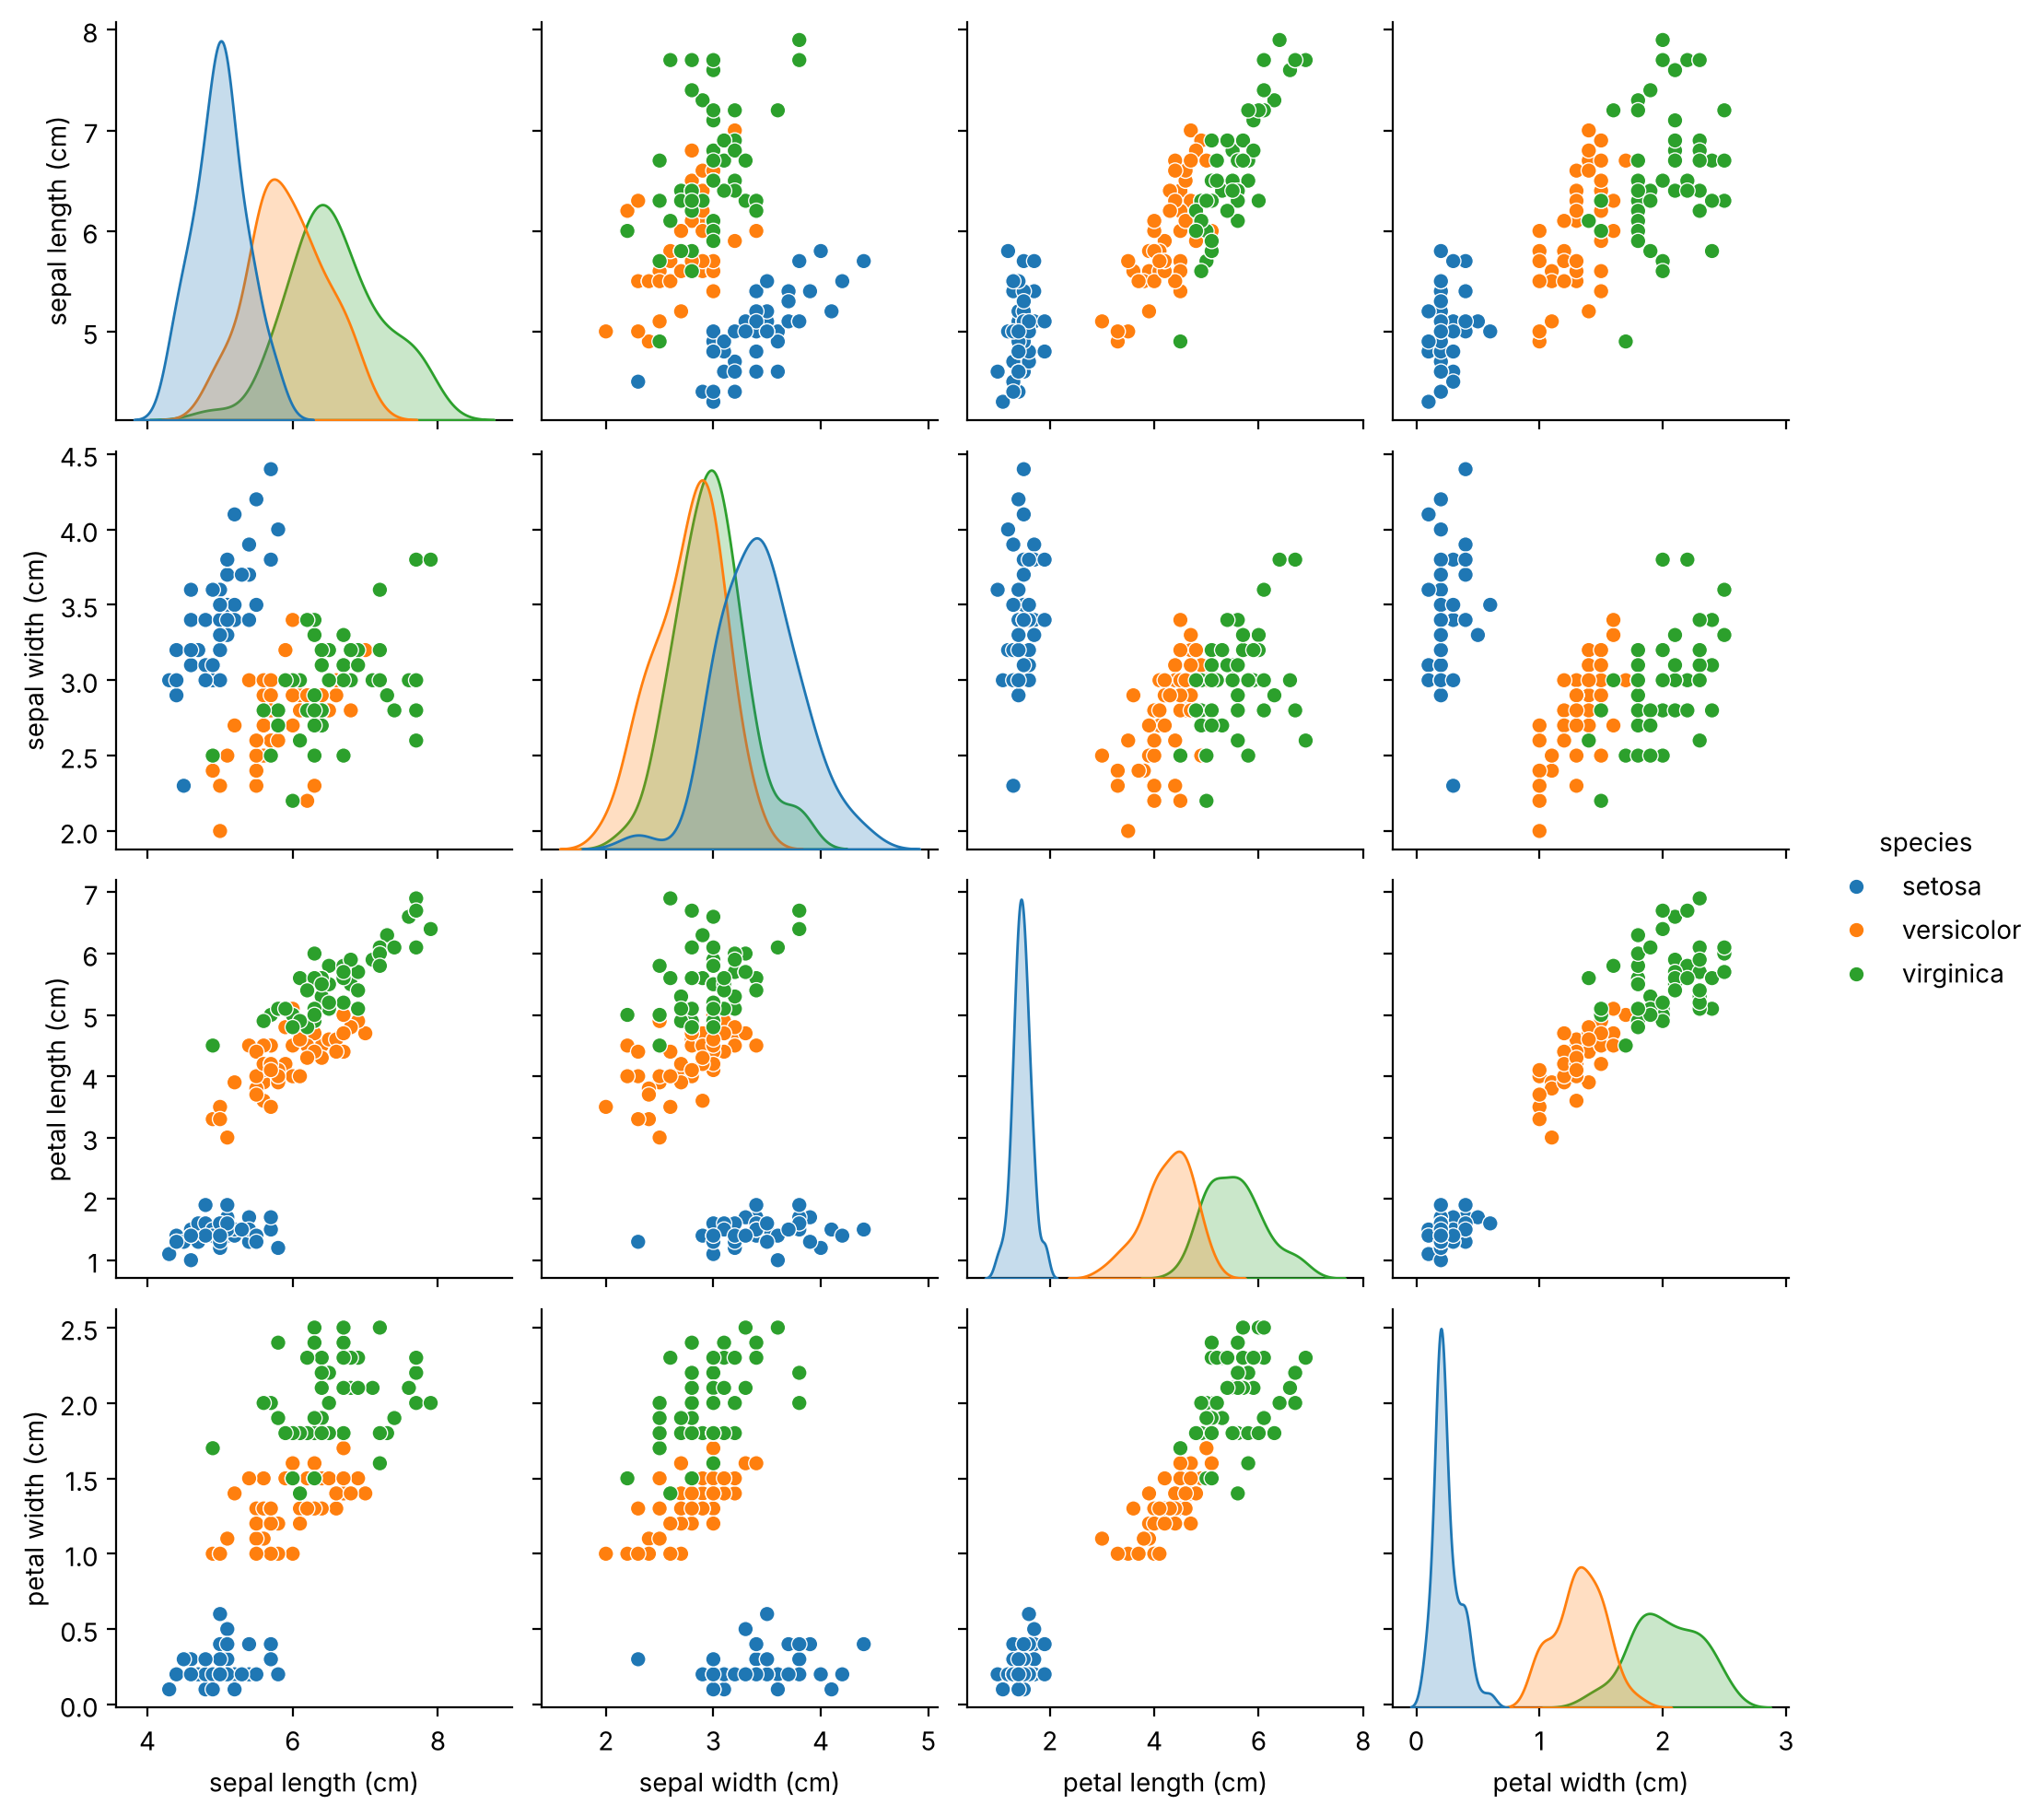

In [5]:
# Scatter plot of every feature pair, colored by species, to see how well the classes separate
# (drop the numeric target since 'species' already carries the same information)
sns.pairplot(df.drop(columns='target'), hue='species')
plt.show()

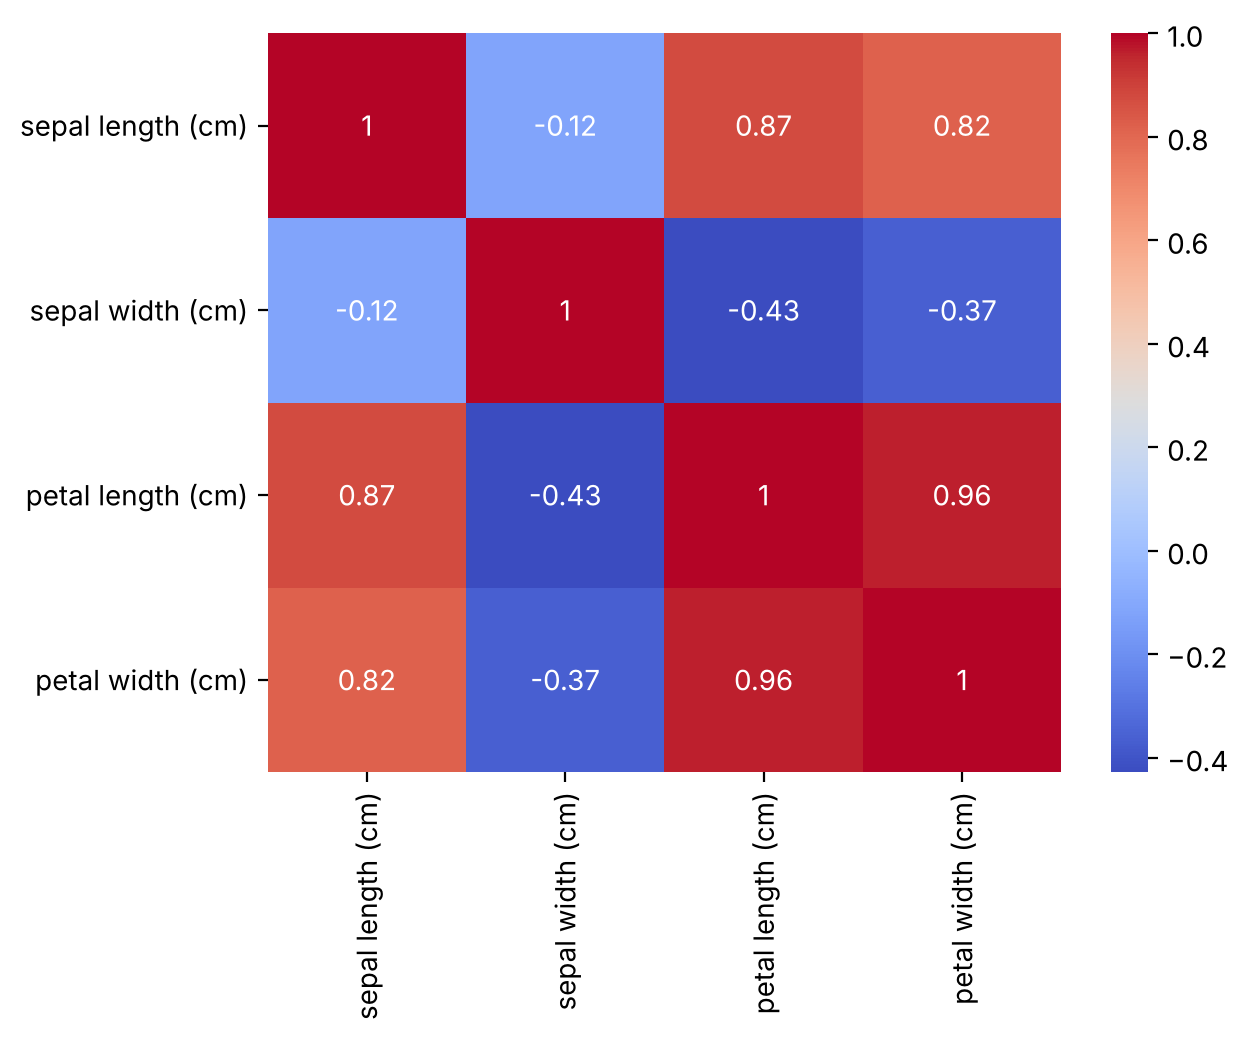

In [6]:
# Correlation heatmap of the four measurement features only
# annot=True prints each correlation value inside its cell
sns.heatmap(df.drop(columns=['target', 'species']).corr(), annot=True, cmap='coolwarm')
plt.show()

**Observations:**

- **Setosa is clearly separated** from the other two species in nearly every feature pair, so it should be easy to classify.
- **Versicolor and virginica overlap slightly**, so most classification errors will likely be between these two.
- **Petal length and petal width separate the species best.** They are also highly correlated with each other, so they carry similar information.

## 3. Train/Test Split

The data is split into **70% training (105 samples)** and **30% testing (45 samples)**.

- `stratify=y` keeps the same 1:1:1 species ratio in both sets, so the test set isn't missing or overweighting any class.
- `random_state=42` makes the split reproducible, so results are the same every run.

In [7]:
# Features (the four measurements) and labels (species as 0/1/2)
X = df[iris.feature_names]
y = df['target']

# Hold out 30% of the data for testing.
# stratify=y keeps the same species proportions in both sets;
# random_state=42 makes the split reproducible.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 105
Testing samples: 45


## 4. Feature Scaling

SVMs depend on distances between points, so a feature with a larger range would otherwise dominate the model. `StandardScaler` rescales each feature to **mean 0 and standard deviation 1**.

The scaler is **fit on the training set only** and then applied to the test set. Fitting it on all the data would leak information about the test set into training.

*(The decision tree doesn't need scaling, because each split looks at only one feature at a time.)*

In [8]:
# Standardize features to mean 0 and standard deviation 1.
# SVMs are distance-based, so features on larger scales would otherwise dominate.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # learn mean/std from training data only
X_test_scaled = scaler.transform(X_test)        # reuse those values so no test info leaks into training

## 5. Model 1: SVM Without a Kernel (Linear SVM)

A linear SVM uses no kernel transformation. It works directly in the original feature space and finds the hyperplane that separates the classes with the **widest possible margin**. For three classes, scikit-learn trains several one-vs-one classifiers and combines their votes.

- `kernel='linear'`: no kernel trick, so the boundaries are straight lines/planes
- `C=1`: the regularization strength. A smaller `C` allows a wider margin with more training mistakes, and a larger `C` fits the training data more tightly.

In [9]:
# Linear SVM: finds straight-line (hyperplane) boundaries between classes.
# C=1 controls the trade-off between a wide margin and misclassified training points.
svm_linear = SVC(kernel='linear', C=1)
svm_linear.fit(X_train_scaled, y_train)

# Predict on the scaled test set and measure accuracy
pred_linear = svm_linear.predict(X_test_scaled)
acc_linear = accuracy_score(y_test, pred_linear)
print("Linear SVM test accuracy:", round(acc_linear, 4))

Linear SVM test accuracy: 0.9111


## 6. Model 2: SVM With a Kernel (RBF Kernel)

The **Radial Basis Function (RBF)** kernel implicitly maps the data into a higher-dimensional space (the *kernel trick*), which lets the SVM draw **curved boundaries** in the original feature space. This can help where versicolor and virginica overlap.

- `kernel='rbf'`: the Gaussian kernel
- `C=1`: same regularization trade-off as above
- `gamma='scale'`: sets how far each training point's influence reaches, computed automatically from the data's variance

In [10]:
# RBF (Gaussian) kernel SVM: can learn curved, non-linear boundaries.
# gamma='scale' sets the kernel width automatically from the data's variance.
svm_rbf = SVC(kernel='rbf', C=1, gamma='scale')
svm_rbf.fit(X_train_scaled, y_train)

# Predict on the scaled test set and measure accuracy
pred_rbf = svm_rbf.predict(X_test_scaled)
acc_rbf = accuracy_score(y_test, pred_rbf)
print("RBF SVM test accuracy:", round(acc_rbf, 4))

RBF SVM test accuracy: 0.9333


## 7. Model 3: Decision Tree

A decision tree learns a sequence of **if/then rules** on individual features (e.g., *"petal length ≤ 2.45 cm → setosa"*). It is trained on the **unscaled** features, so the split thresholds stay in real centimeters and are easy to read.

`max_depth=3` limits the tree to three levels of questions, which reduces overfitting and keeps the tree small enough to visualize.

In [11]:
# Decision tree for comparison. Trees split on one feature at a time,
# so they don't need scaled data; we use the original unscaled features.
# max_depth=3 limits the tree's size to reduce overfitting and keep it readable.
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)

# Predict on the test set and measure accuracy
pred_tree = tree.predict(X_test)
acc_tree = accuracy_score(y_test, pred_tree)
print("Decision Tree test accuracy:", round(acc_tree, 4))

Decision Tree test accuracy: 0.9778


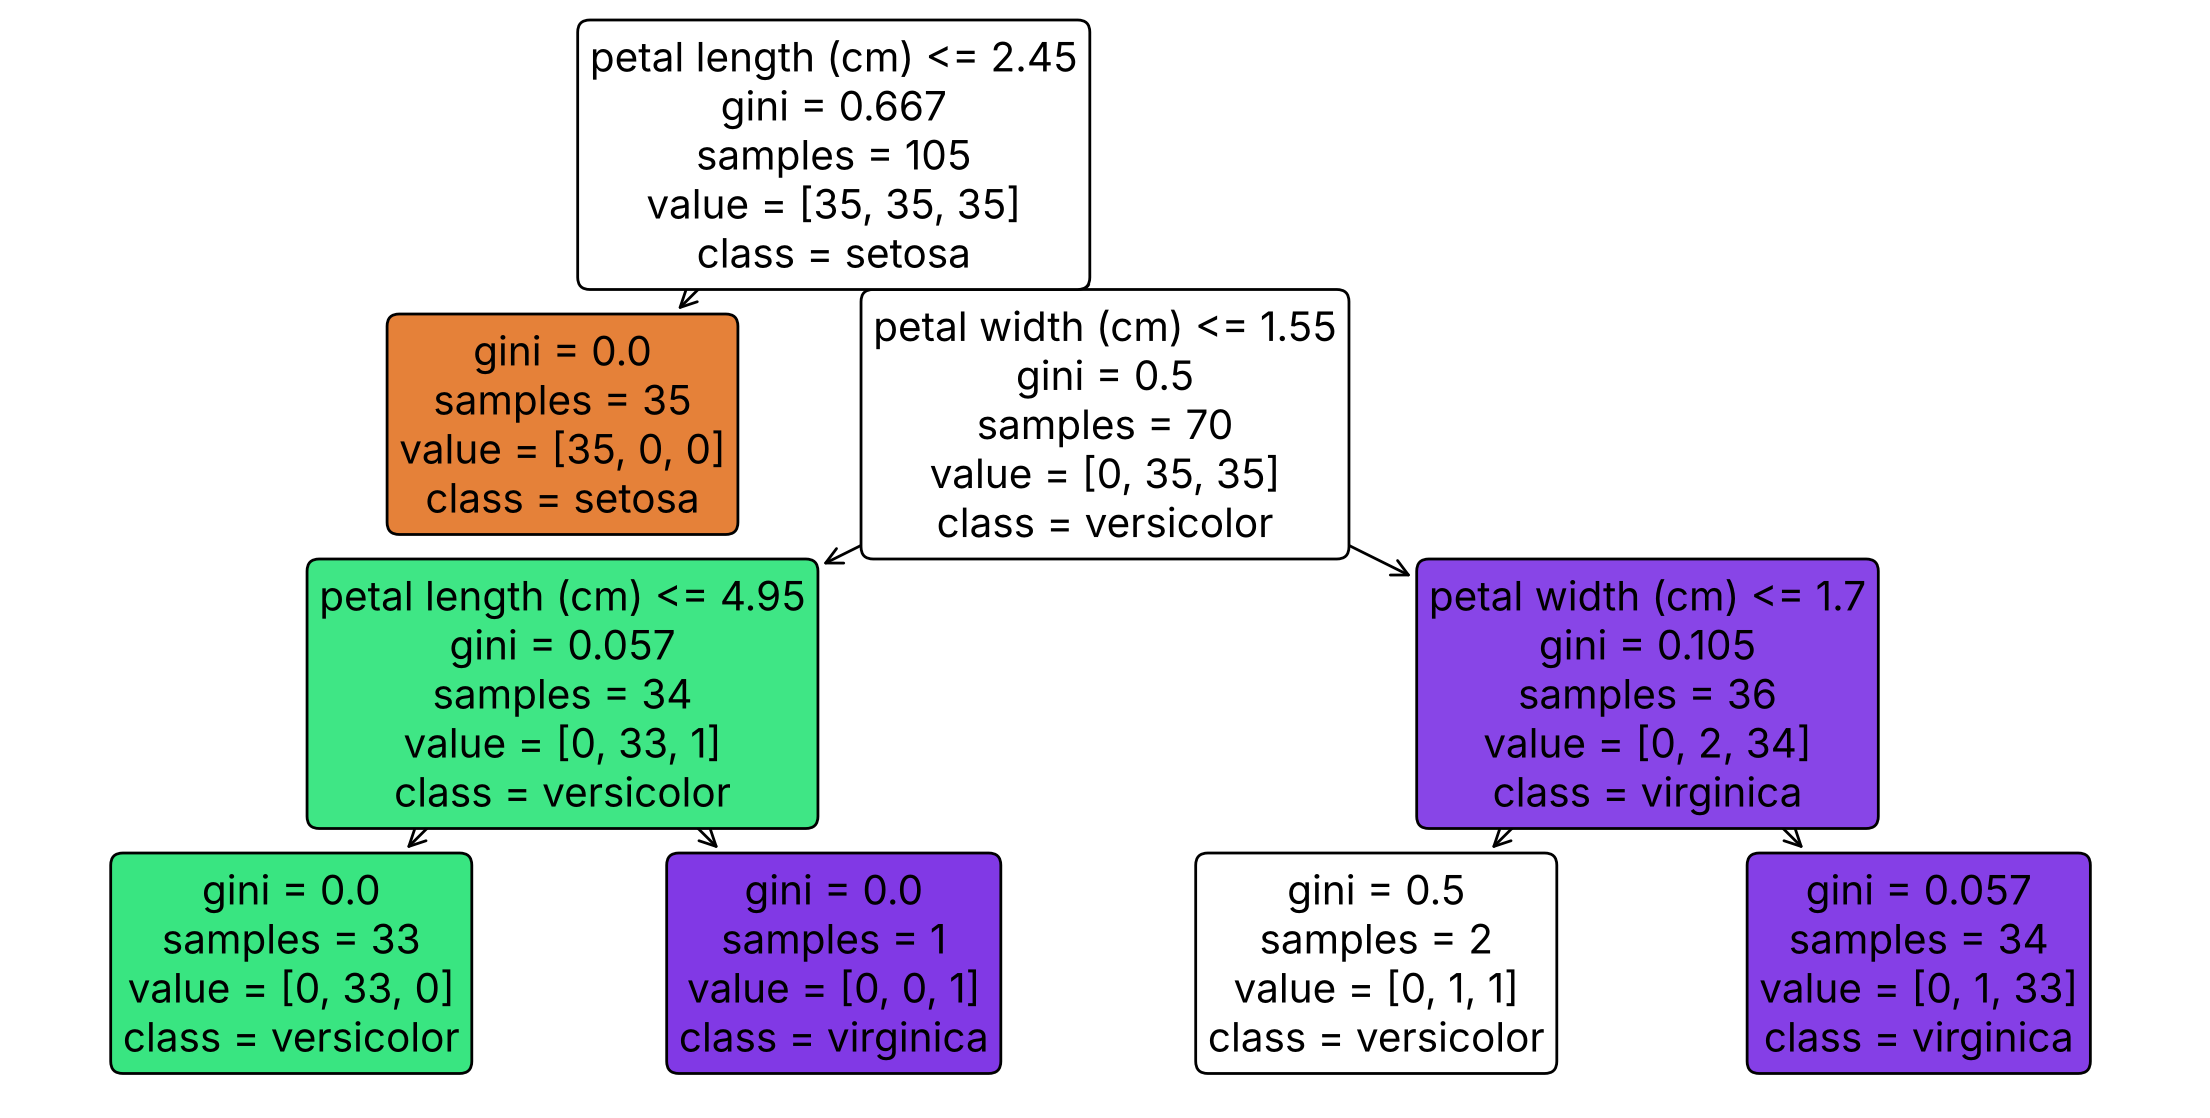

In [12]:
# Draw the trained tree: each node shows its split rule, Gini impurity,
# sample count, and class breakdown; color indicates the majority class.
plt.figure(figsize=(14, 7))
plot_tree(tree, feature_names=iris.feature_names, class_names=list(iris.target_names),
          filled=True, rounded=True)
plt.show()

## 8. Model Comparison

The table below lists each model's test accuracy, and the confusion matrices show **where** each model makes mistakes.

**How to read a confusion matrix:** rows are the true species and columns are the predicted species. Numbers on the diagonal are correct predictions, and anything off the diagonal is a misclassification.

           Model  Test accuracy
0     Linear SVM       0.911111
1        RBF SVM       0.933333
2  Decision Tree       0.977778


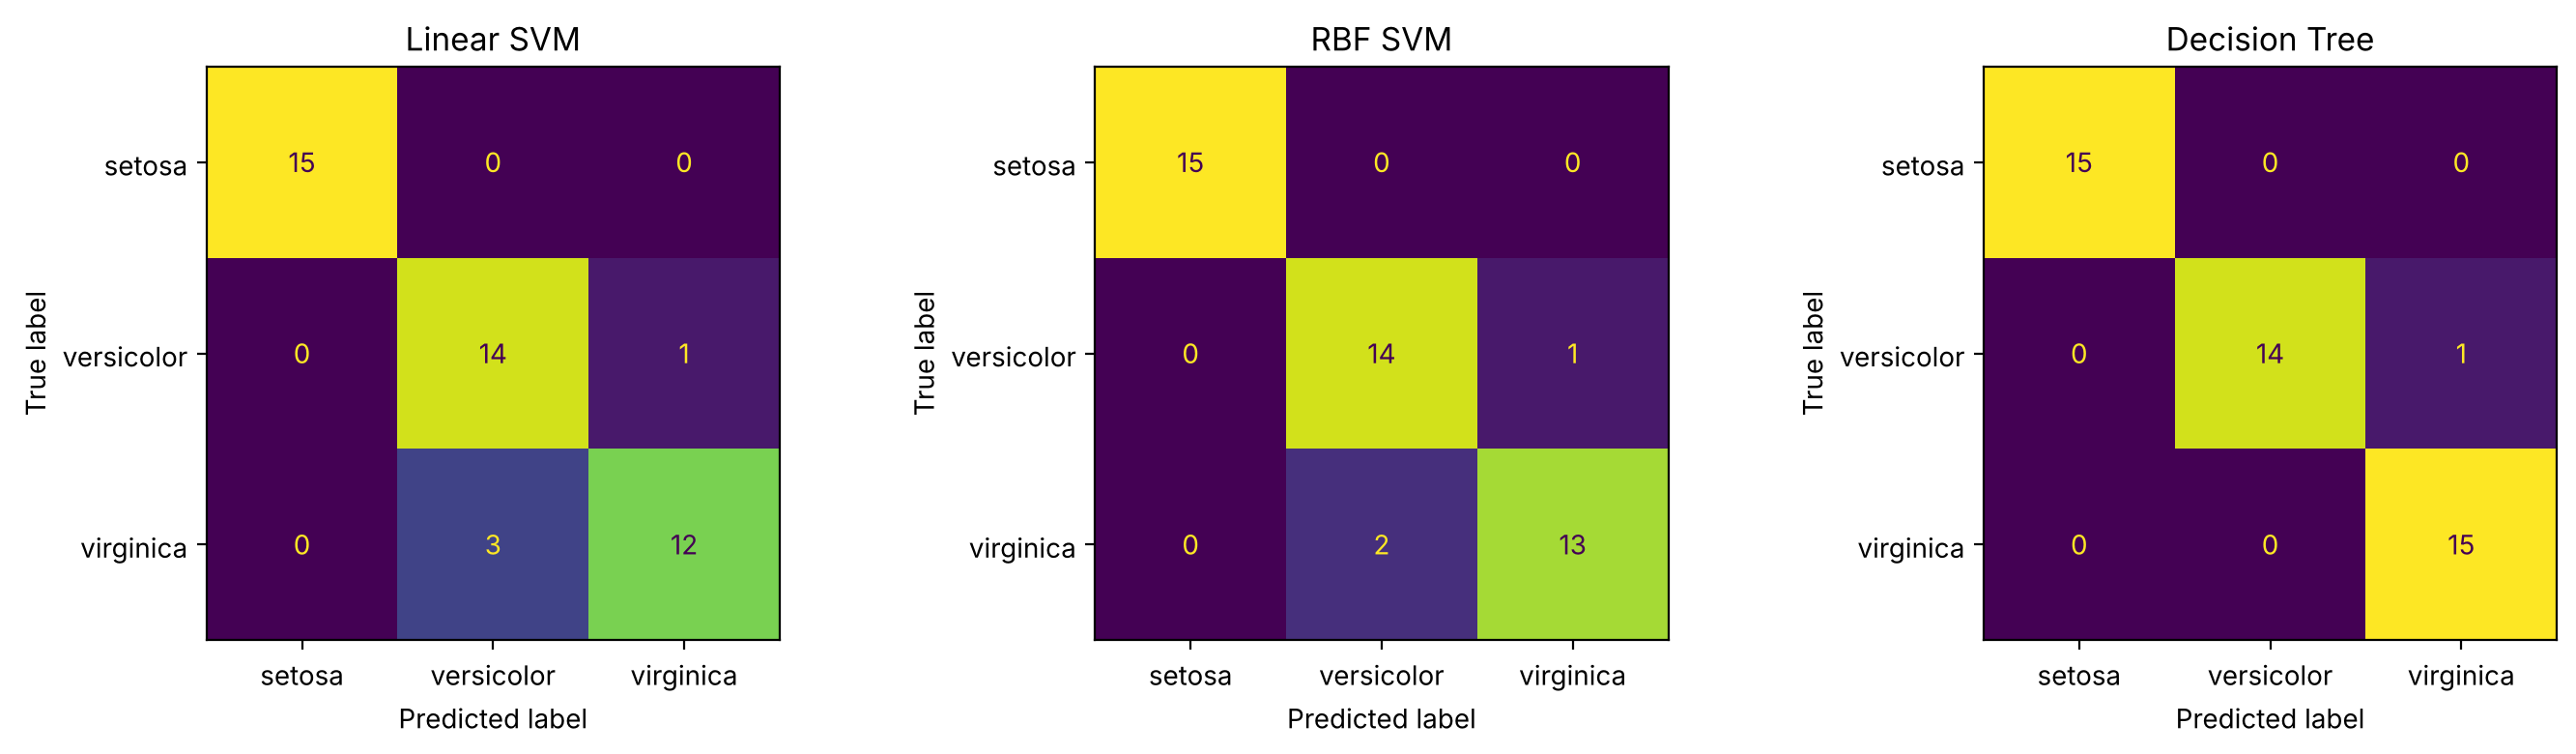

In [13]:
# Collect the three models' test accuracies into one table for comparison
results = pd.DataFrame({
    'Model': ['Linear SVM', 'RBF SVM', 'Decision Tree'],
    'Test accuracy': [acc_linear, acc_rbf, acc_tree]})
print(results)

# Plot a confusion matrix for each model side by side.
# Rows are true species, columns are predicted species; off-diagonal cells are errors.
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, name, pred in zip(axes, results['Model'], [pred_linear, pred_rbf, pred_tree]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=iris.target_names).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()  # prevent subplot titles/labels from overlapping
plt.show()

## 9. Conclusion

| Model | Test Accuracy | Misclassified (of 45) |
|---|---|---|
| Linear SVM (no kernel) | 91.1% | 4 |
| RBF SVM (kernel) | 93.3% | 3 |
| Decision Tree | **97.8%** | 1 |

**Key findings:**

- **Setosa was classified perfectly by every model.** This matches the EDA, where setosa was clearly separated from the other two species.
- **All errors were between versicolor and virginica**, the two species that overlap in the pair plot.
- **The kernel (RBF) SVM did slightly better than the SVM without a kernel** (one fewer error), because its curved boundary handles the versicolor/virginica overlap a bit better.
- **The decision tree scored highest.** It split mainly on **petal length and petal width**, the same features the EDA identified as the most informative.

**Caveat:** with only 45 test samples, each error changes accuracy by about 2.2 percentage points, so the gaps between models amount to just one to three flowers. A different random split could change the ranking. Cross-validation (e.g., `cross_val_score` with 5 or 10 folds) would give a more reliable comparison.